# DAY1 실습 03 — 시각화 기초



In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 1. 그래프 고르기

그래프는 **확인하려는 질문**과 **변수의 종류**로 고른다.

| 확인하려는 질문 | 변수 | 그래프 | 예 |
|---|---|---|---|
| 범주마다 몇 개인가? | 범주형 1개 | 막대그래프 | Type별 기록 수 |
| 범주마다 비율·평균이 다른가? | 범주형 + 요약값 | 막대그래프 | Type별 고장률 |
| 숫자가 어떻게 분포하는가? | 수치형 1개 | 히스토그램 | 토크 분포 |
| 집단마다 숫자 분포가 다른가? | 범주형 + 수치형 | 박스플롯 | Type별 토크 |
| 두 숫자가 함께 움직이는가? | 수치형 2개 | 산점도 | 회전속도와 토크 |
| 시간에 따라 어떻게 변하는가? | 시간 + 수치형 | 선그래프 | 월별 불량률 |
| 여러 숫자끼리 관계는? | 수치형 여러 개 | 히트맵 | 상관계수 표 |

막대그래프와 히스토그램은 모양이 비슷하지만 다르다. 막대그래프의 가로축은 **범주**(L·M·H)이고, 히스토그램의 가로축은 **숫자 구간**이다.

## 2. 그래프를 그리는 세 가지 도구

| 도구 | 정의 | 사용 |
|---|---|---|
| Matplotlib | 파이썬 그래프의 기본 틀. 제목·축·크기·선 같은 그림의 모든 부분을 다룬다 | 꾸미기 (`plt.title`, `plt.xlabel` 등) |
| Pandas | 데이터에서 바로 `.hist()`, `.plot.box()`처럼 그린다 | 빠르게 모양 확인 |
| Seaborn | 열 이름만 지정하면 통계 그래프를 그린다 | 집단 비교, 색으로 구분 |

Pandas와 Seaborn은 모두 안에서 Matplotlib을 쓴다. 그래서 어느 도구로 그리든 `plt.title()`, `plt.xlabel()`, `plt.show()`로 똑같이 꾸미고 표시한다.

### 2-1. 차트별 지원 함수

| 차트 | Pandas | Matplotlib | Seaborn | 비고 |
|---|---|---|---|---|
| 히스토그램 | `Series.hist()` | `plt.hist()` | `sns.histplot()` | 세 도구 모두 지원 |
| 막대그래프 | `Series.plot.bar()` | `plt.bar(x, height)` | `sns.countplot()`, `sns.barplot()` | `countplot`은 원자료의 행 수를 직접 센다. Pandas·Matplotlib은 `value_counts()` 등으로 먼저 집계한 값을 그린다 |
| 박스플롯 (변수 1개) | `Series.plot.box()` | `plt.boxplot()` | `sns.boxplot()` | 세 도구 모두 지원 |
| 박스플롯 (집단별) | `DataFrame.boxplot(column=, by=)` | `plt.boxplot([], tick_labels=[])` | `sns.boxplot(x=, y=)` | Matplotlib은 집단별로 직접 나눠 목록으로 넣는다 |
| 산점도 | `DataFrame.plot.scatter(x=, y=)` | `plt.scatter()` | `sns.scatterplot()` | 세 도구 모두 지원 |
| 범주별 색 구분 | `c=`로 숫자 열 값을 색으로 표시 (범주 범례는 만들지 않음) | 범주별로 나눠 그린 뒤 `plt.legend()` | `hue="열"` | 범주별 색과 범례를 한 번에 만드는 것은 Seaborn |
| 선그래프 | `Series.plot()` | `plt.plot()` | `sns.lineplot()` | 세 도구 모두 지원. `sns.lineplot`은 같은 x에 값이 여러 개면 평균과 신뢰구간을 그린다 |
| 히트맵 | 미지원 | `plt.imshow()` (칸 숫자는 `plt.text()`로 직접 표기) | `sns.heatmap(annot=True)` | 칸 숫자까지 표시하는 히트맵은 Seaborn |
| 구간 경계·개수 반환 | 미지원 | `plt.hist()`가 (개수, 경계, 막대)를 반환 | 미지원 | Matplotlib |
| 여러 칸 배치·파일 저장 | — | `plt.subplots()`, `plt.savefig()` | — | Matplotlib. Pandas·Seaborn 그래프도 `ax=`로 칸을 지정해 그린다 |

### 2-2. 매개변수(옵션)의 적용 범위

Pandas와 Seaborn의 그래프 함수는 직접 처리하지 않는 키워드 인수를 Matplotlib에 그대로 전달한다. 그래서 그림 모양을 정하는 매개변수는 세 도구에서 같은 이름으로 쓴다. 반면 데이터를 지정하는 방식에 관한 매개변수는 도구마다 다르다.

| 구분 | 매개변수 | 적용 범위 | 설명 |
|---|---|---|---|
| 공통 스타일 | `color`, `edgecolor`, `alpha`, `linestyle`, `marker`, `label` | 세 도구 공통 | Matplotlib 매개변수. Pandas·Seaborn이 Matplotlib에 전달한다 |
| 차트별 | `bins` | 히스토그램 함수 | 세 도구의 히스토그램 함수에서 같은 이름으로 쓴다 |
| 차트별 | `whis`, `showmeans`, `showfliers` | 박스플롯 함수 | Matplotlib `boxplot`의 매개변수. 세 도구의 박스플롯 함수에서 쓴다 |
| 차트별 | `s` | 산점도 함수 | 점 크기. 세 도구의 산점도 함수에서 쓴다 |
| Seaborn 전용 | `data`, `x`, `y`, `hue`, `order` | Seaborn | 표(`data`)와 열 이름으로 그릴 변수를 지정한다 |
| Pandas 전용 | `rot`, `grid`, `figsize` | Pandas | 그리는 함수 안에서 글자 각도·격자·그림 크기를 지정한다 |
| 칸 지정 | `ax` | Pandas, Seaborn | `plt.subplots()`로 만든 칸에 그린다  |

공식 문서 : [pandas DataFrame.plot (kwargs 전달)](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html) · [Seaborn 데이터 구조](https://seaborn.pydata.org/tutorial/data_structure.html) · [Seaborn 함수 개요](https://seaborn.pydata.org/tutorial/function_overview.html) · [Matplotlib pyplot](https://matplotlib.org/stable/api/pyplot_summary.html)

### 2-3. 코드에서 도구를 구분하는 법



| 코드 모양 | 도구 | 예 |
|---|---|---|
| `데이터.hist()`, `데이터.plot.bar()`처럼 **데이터 뒤에 점을 찍고** 그린다 | Pandas | `torque.hist(bins=30)` |
| `plt.`으로 시작한다 | Matplotlib | `plt.hist(torque)`, `plt.title("제목")` |
| `sns.`으로 시작한다 | Seaborn | `sns.histplot(torque)`, `sns.boxplot(...)` |

### 2-4. 세 도구로 같은 히스토그램 그리기

**히스토그램 주요 옵션** (세 도구 공통)

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `bins` | 구간 개수 (또는 구간 경계) | `bins=30` |
| `color` | 막대 색 | `color="skyblue"` |
| `edgecolor` | 막대 테두리 색. 막대 사이가 구분되어 보인다 | `edgecolor="white"` |


공식 문서 : [Matplotlib 시작하기](https://matplotlib.org/stable/users/explain/quick_start.html) · [Pandas 시각화](https://pandas.pydata.org/docs/user_guide/visualization.html) · [Seaborn 함수 개요](https://seaborn.pydata.org/tutorial/function_overview.html)

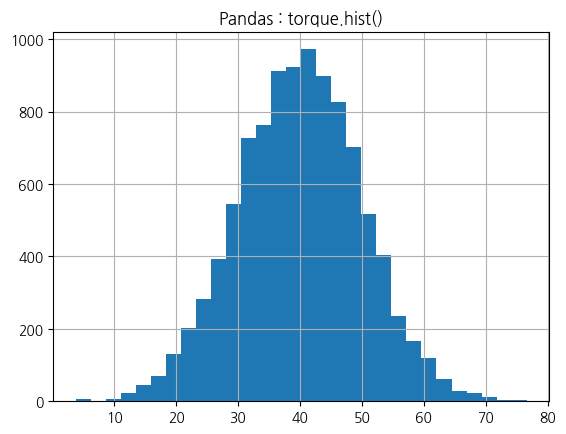

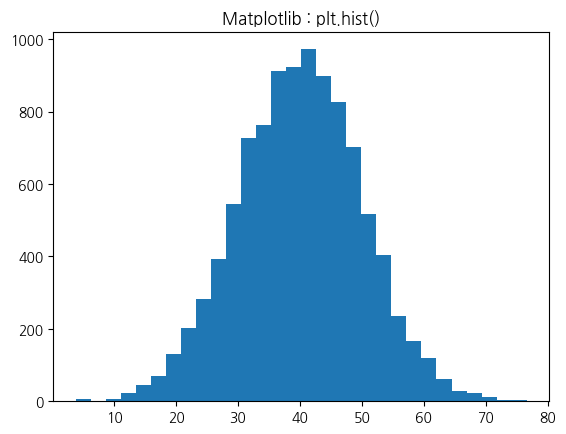

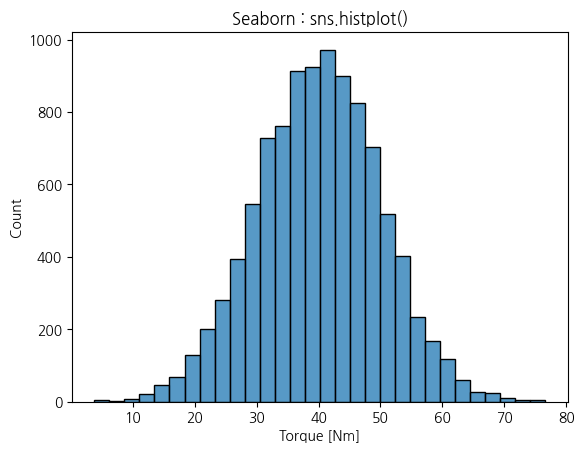

In [ ]:
torque = data["Torque [Nm]"]

# 1) Pandas : 데이터 뒤에 .hist()
torque.hist(bins=30)
plt.title("Pandas : torque.hist()")
plt.show()

# 2) Matplotlib : plt.hist(데이터)
plt.hist(torque, bins=30)
plt.title("Matplotlib : plt.hist()")
plt.show()

# 3) Seaborn : sns.histplot(데이터)
sns.histplot(torque, bins=30)
plt.title("Seaborn : sns.histplot()")
plt.show()

세 그래프 모두 가로축은 토크 구간(Nm), 세로축은 그 구간의 기록 수다. 같은 자료라 막대 모양은 같고, 격자·색·축 이름 같은 기본 모양만 도구마다 다르다.

## 3. 그래프 꾸미기 기본

사용 도구 : Matplotlib (`plt.`) — Pandas·Seaborn으로 그린 그래프에도 똑같이 쓴다

| 코드 | 하는 일 |
|---|---|
| `plt.figure(figsize=(가로, 세로))` | 그림 크기 (단위 : 인치) |
| `plt.title("제목")` | 그래프 제목 |
| `plt.xlabel("이름")`, `plt.ylabel("이름")` | 가로축·세로축 이름 (단위를 같이 적는다) |
| `color="색"` | 막대·선·점의 색 |
| `plt.axvline(값)`, `plt.axhline(값)` | 세로 기준선, 가로 기준선 |
| `label="이름"` + `plt.legend()` | 범례 (선이나 점이 무엇인지 표시) |
| `plt.show()` | 그래프 표시 (항상 마지막) |

**선 옵션** (`axvline`, `axhline`, `plot`에 공통)

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `color` | 선 색 | `color="red"` |
| `linestyle` | 선 모양 | `"-"` 실선, `"--"` 점선, `":"` 짧은 점선 |
| `label` | 범례에 표시할 이름 | `label="평균"` |

공식 문서 : [axvline](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.axvline.html) · [legend](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html)

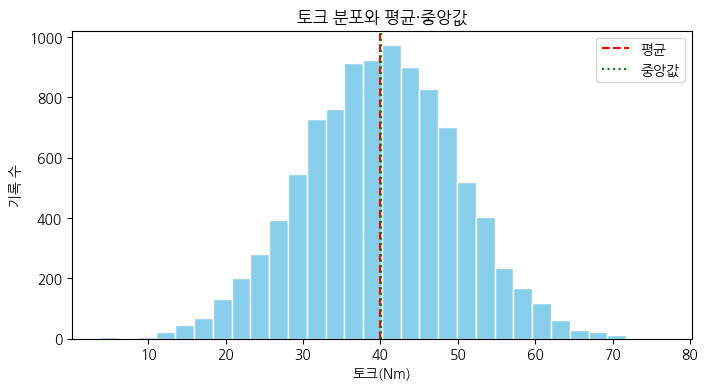

In [ ]:
# [Matplotlib] 히스토그램 + 기준선
# 토크 히스토그램에 평균선과 중앙값선을 그린다
plt.figure(figsize=(8, 4))                         # figure : 그림 크기
plt.hist(torque, bins=30, color="skyblue", edgecolor="white")

# axvline : 세로선 / linestyle="--" : 점선
plt.axvline(torque.mean(), color="red", linestyle="--", label="평균")
plt.axvline(torque.median(), color="green", linestyle=":", label="중앙값")

plt.title("토크 분포와 평균·중앙값")
plt.xlabel("토크(Nm)")
plt.ylabel("기록 수")
plt.legend()                                       # legend : label 을 모아 범례로 표시
plt.show()

빨간 점선은 평균, 초록 점선은 중앙값이다. 두 선이 가까우면 좌우 대칭에 가까운 분포이고, 평균이 중앙값보다 한쪽 꼬리 쪽에 있으면 그쪽으로 치우친 분포이다.

## 4. 범주형 변수 : 막대그래프

막대그래프는 범주마다 값 하나를 막대 높이로 그린다. 그리기 전에 **막대 높이가 무엇인지**(개수인지, 비율인지, 평균인지)를 먼저 정한다.

사용 도구 : Pandas (`.plot.bar()`) + Matplotlib (꾸미기)

순서는 항상 먼저 숫자를 계산하고(`value_counts`, `groupby`) → 그 결과에 `.plot.bar()`다.

**주요 옵션**

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `color` | 막대 색 | `.plot.bar(color="steelblue")` |
| `plt.xticks(rotation=0)` | 가로축 글자 각도. Pandas 막대그래프는 글자가 90도로 누워 나오므로 0으로 세운다 | `plt.xticks(rotation=0)` |

공식 문서 : [Series.plot.bar](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.bar.html) · [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html)

### 4-1. 범주별 개수

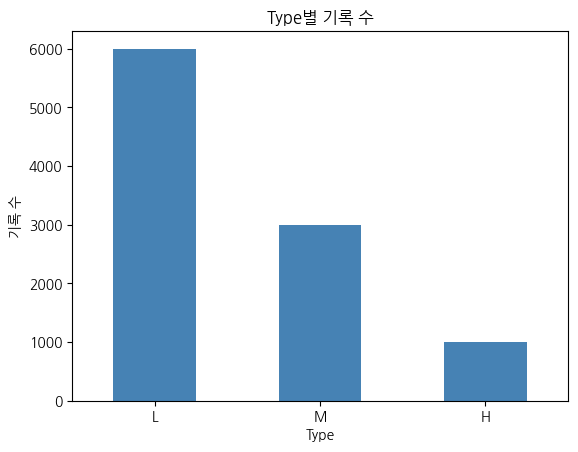

In [ ]:
# [Pandas] 막대그래프
# 1) 범주별 개수를 먼저 센다 (01-1 의 value_counts)
type_cnt = data["Type"].value_counts()

# 2) 센 결과를 막대그래프로
type_cnt.plot.bar(color="steelblue")
plt.title("Type별 기록 수")
plt.xlabel("Type")
plt.ylabel("기록 수")
plt.xticks(rotation=0)                             # xticks : 가로축 글자를 눕히지 않고 바로 세운다
plt.show()

가로축은 범주(L·M·H), 세로축은 기록 수다. 막대 높이가 범주별 기록 수를 나타낸다.

### 4-2. 범주별 요약값 : Type별 고장률

`groupby` 는 범주별로 묶어서 계산한다. `data.groupby("Type")["Machine failure"].mean()` 은 Type마다 고장(0/1) 열의 평균, 즉 고장률을 구한다 (01-1 의 "0/1 평균 = 비율").

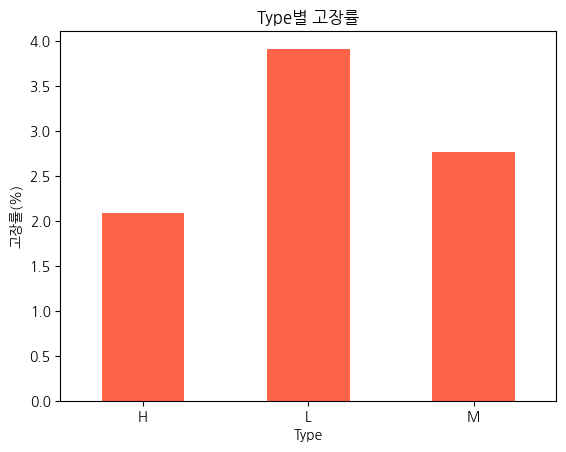

In [ ]:
# [Pandas] 막대그래프
# 1) Type 별 고장률(%) 계산
fail_rate = data.groupby("Type")["Machine failure"].mean() * 100

# 2) 막대그래프
fail_rate.plot.bar(color="tomato")
plt.title("Type별 고장률")
plt.xlabel("Type")
plt.ylabel("고장률(%)")
plt.xticks(rotation=0)
plt.show()

4-1과 모양은 같지만 세로축이 다르다. 여기서 막대 높이는 기록 수가 아니라 **고장률(%)**이다. 막대그래프는 세로축이 무엇인지에 따라 해석이 달라진다.

## 5. 히스토그램 : 구간과 빈도

히스토그램은 숫자를 일정한 구간으로 나누고 구간마다 개수를 센 뒤 막대로 그린다.   

최솟값·최댓값 확인 → 구간 나누기 → 구간별 개수 세기 → 막대 그리기

`plt.hist()`는 그래프를 그리면서 **구간 경계**와 **구간별 개수**도 돌려준다.


**`plt.hist()`가 돌려주는 값**

| 이름 | 내용 |
|---|---|
| `counts` | 구간별 개수 |
| `edges` | 구간 경계 (구간 수 + 1개) |

| 구간 (bins=5, 너비 8) | 포함되는 값 | 개수 |
|---|---|---:|
| 10 이상 ~ 18 미만 | 10, 12 | 2 |
| 18 이상 ~ 26 미만 | 18, 19, 20, 21 | 4 |
| 26 이상 ~ 34 미만 | 26 | 1 |
| 34 이상 ~ 42 미만 | 36 | 1 |
| 42 이상 ~ 50 이하 | 45, 50 | 2 |

구간의 시작값은 포함하고 끝값은 포함하지 않는다. 마지막 구간만 최댓값까지 포함한다.

공식 문서 : [pyplot.hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)

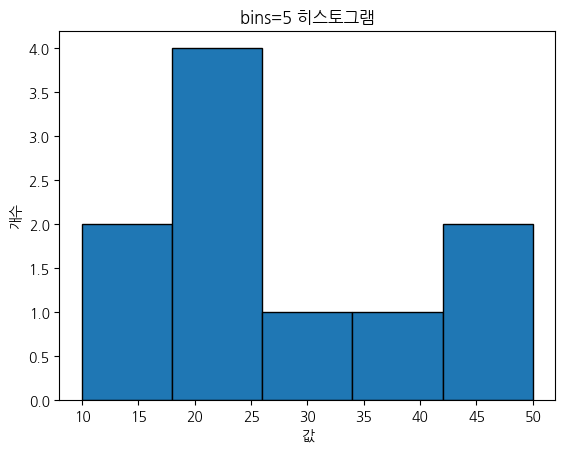

구간 경계: [10. 18. 26. 34. 42. 50.]
구간별 개수: [2. 4. 1. 1. 2.]


In [ ]:
# [Matplotlib] 히스토그램 (구간 경계·개수 돌려받기)
# 1) 작은 예제 자료 (10개)
scores = [10, 12, 18, 19, 20, 21, 26, 36, 45, 50]

# 2) 5개 구간으로 히스토그램을 그리고, 돌려주는 값 세 개를 받는다
#    counts : 구간별 개수 / edges : 구간 경계
counts, edges, patches = plt.hist(scores, bins=5, edgecolor="black")
plt.title("bins=5 히스토그램")
plt.xlabel("값")
plt.ylabel("개수")
plt.show()

print("구간 경계:", edges)
print("구간별 개수:", counts)

막대 다섯 개가 위 표의 다섯 구간이다. 구간 경계는 10, 18, 26, 34, 42, 50이고, 막대 높이는 구간별 개수 2, 4, 1, 1, 2이다.

## 6. 박스플롯 : 옵션과 집단 비교


| 옵션 | 기본값 | 하는 일 |
|---|---|---|
| `whis` | 1.5 | 수염 기준 (IQR의 몇 배까지) |
| `showmeans` | False | True이면 평균을 삼각형으로 표시 |
| `showfliers` | True | False이면 수염 밖 이상값 후보 점을 숨김 |

집단별로 나란히 비교할 때는 Seaborn의 `sns.boxplot()`을 쓴다. 열 이름만 지정하면 범주마다 상자를 하나씩 그린다.

**`sns.boxplot()` 주요 옵션**

| 옵션 | 하는 일 | 예 |
|---|---|---|
| `data` | 사용할 표 | `data=data` |
| `x` | 가로축에 놓을 범주 열 | `x="Type"` |
| `y` | 세로축에 놓을 숫자 열 | `y="Torque [Nm]"` |
| `order` | 상자 순서 | `order=["L", "M", "H"]` |

공식 문서 : [Series.plot.box](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.box.html) · [seaborn.boxplot](https://seaborn.pydata.org/generated/seaborn.boxplot.html)

### 6-1. 이상값 후보 점 숨기기

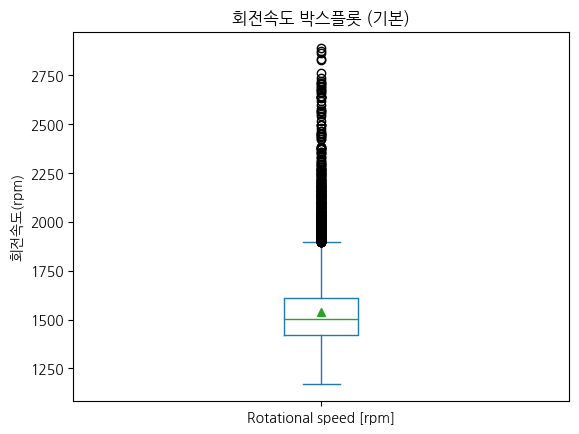

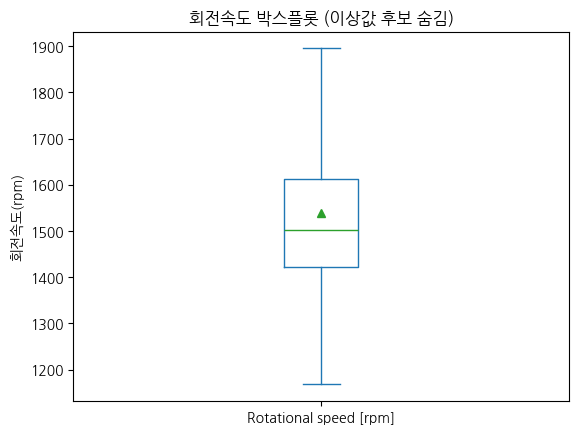

In [ ]:
# [Pandas] 박스플롯
speed = data["Rotational speed [rpm]"]

# 1) 기본 : 이상값 후보 점 표시
speed.plot.box(showmeans=True)
plt.title("회전속도 박스플롯 (기본)")
plt.ylabel("회전속도(rpm)")
plt.show()

# 2) showfliers=False : 점을 숨긴다
speed.plot.box(showmeans=True, showfliers=False)
plt.title("회전속도 박스플롯 (이상값 후보 숨김)")
plt.ylabel("회전속도(rpm)")
plt.show()

두 그래프는 같은 데이터다. 두 번째 그래프는 동그라미가 사라지면서 세로축 범위가 좁아져 상자가 크게 보인다. `showfliers=False`는 점을 화면에서만 숨기며 데이터에서 지우지 않는다.

### 6-2. Type별 토크 비교

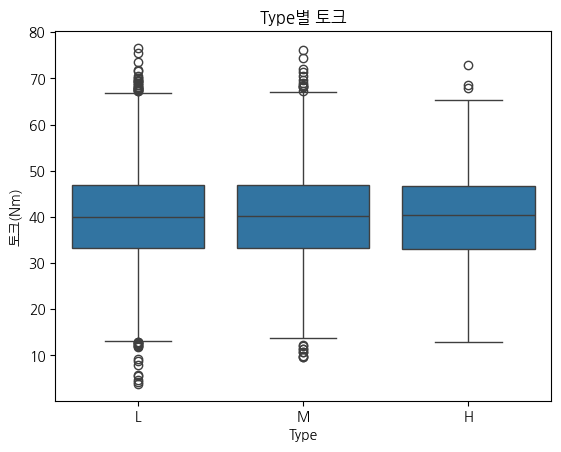

In [ ]:
# [Seaborn] 집단별 박스플롯
# boxplot : x 에 범주 열, y 에 숫자 열
# order : 상자 순서 지정 (품질 L → M → H)
sns.boxplot(data=data, x="Type", y="Torque [Nm]", order=["L", "M", "H"])
plt.title("Type별 토크")
plt.xlabel("Type")
plt.ylabel("토크(Nm)")
plt.show()

상자 하나가 Type 하나다. 상자 안의 선은 그 Type의 중앙값, 상자의 길이는 가운데 50%의 퍼짐(IQR)을 나타낸다.

## 10. 여러 그래프 나란히 : `plt.subplots()`

두 그래프를 옆에 나란히 놓고 비교하려면 `plt.subplots()`를 쓴다.



- **Figure** : 그림 전체 (종이 한 장)
- **Axes** : 그래프 한 칸

| 코드 | 배치 | 칸 이름 |
|---|---|---|
| `fig, axes = plt.subplots(1, 2)` | 가로 2칸 | `axes[0]`, `axes[1]` |
| `fig, axes = plt.subplots(2, 1)` | 세로 2칸 | `axes[0]`, `axes[1]` |
| `fig, axes = plt.subplots(2, 2)` | 2행 2열 | `axes[0, 0]`, `axes[0, 1]` 등 |

**주요 옵션과 칸에 그리는 법**

| 코드 | 하는 일 |
|---|---|
| `plt.subplots(행 수, 열 수)` | 칸 배치 |
| `figsize=(가로, 세로)` | 그림 전체 크기 |
| `ax=axes[0]` | 그리는 함수에 넣어 그 칸에 그린다 (Pandas·Seaborn 공통) |
| `axes[0].set_title()` | 칸 제목 (`plt.title()` 대신) |
| `axes[0].set_xlabel()`, `axes[0].set_ylabel()` | 칸의 축 이름 |
| `plt.tight_layout()` | 칸 사이 간격 자동 조정 |

공식 문서 : [pyplot.subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)

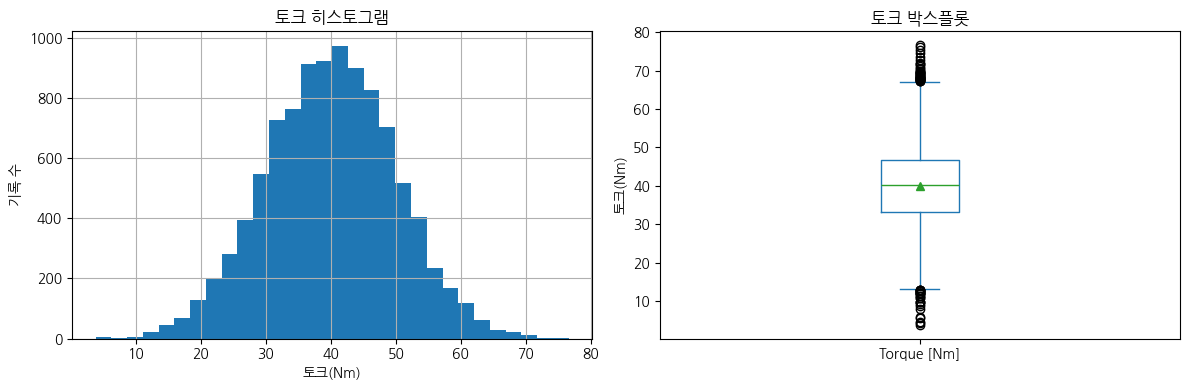

In [ ]:
# [Matplotlib] 칸 나누기 + [Pandas] 히스토그램·박스플롯
# 1) 가로 2칸짜리 그림을 만든다
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 2) 왼쪽 칸 : 히스토그램
torque.hist(bins=30, ax=axes[0])
axes[0].set_title("토크 히스토그램")
axes[0].set_xlabel("토크(Nm)")
axes[0].set_ylabel("기록 수")

# 3) 오른쪽 칸 : 박스플롯
torque.plot.box(showmeans=True, ax=axes[1])
axes[1].set_title("토크 박스플롯")
axes[1].set_ylabel("토크(Nm)")

plt.tight_layout()                                 # tight_layout : 칸 간격 자동 조정
plt.show()

왼쪽과 오른쪽은 같은 토크 데이터다. 박스플롯의 상자(약 33 ~ 47 Nm)는 히스토그램에서 막대가 가장 높게 모인 구간에 해당한다.

## 11. 그래프 저장 : `savefig()`

사용 도구 : Matplotlib (`plt.savefig()`)

보고서에 쓸 그래프는 파일(png)로 저장한다.  
 **`plt.savefig()`는 `plt.show()`보다 먼저** 쓴다.   
 `show()`를 하면 그림이 비워져서 그 뒤에 저장하면 빈 그림이 저장된다.

| 옵션 | 하는 일 |
|---|---|
| `dpi=150` | 해상도 (클수록 선명) |
| `bbox_inches="tight"` | 제목·축 이름이 잘리지 않게 여백을 맞춘다 |

공식 문서 : [pyplot.savefig](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.savefig.html)

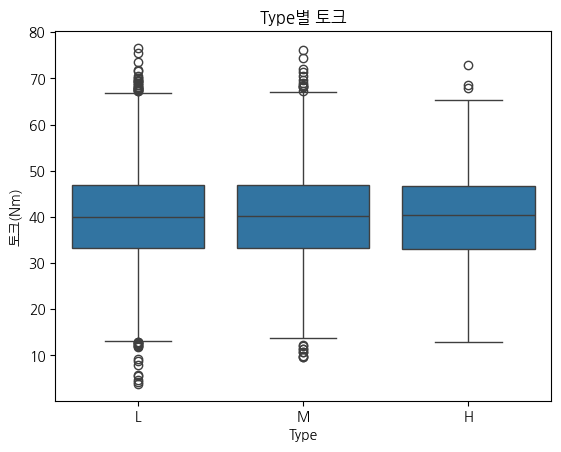

저장: /content/drive/MyDrive/HD-AI/data/Type별_토크_박스플롯.png


In [ ]:
# [Seaborn] 박스플롯 + [Matplotlib] 저장
# 1) 그래프 그리기
sns.boxplot(data=data, x="Type", y="Torque [Nm]", order=["L", "M", "H"])
plt.title("Type별 토크")
plt.ylabel("토크(Nm)")

# 2) 저장 : Drive 의 data 폴더에 png 로
save_path = os.path.join(data_folder, "Type별_토크_박스플롯.png")
plt.savefig(save_path, dpi=150, bbox_inches="tight")

# 3) 표시는 저장 다음에
plt.show()
print("저장:", save_path)

## 12. 정리

| 질문 | 그래프 | 코드 | 도구 |
|---|---|---|---|
| 범주마다 몇 개인가? | 막대그래프 | `data["열"].value_counts().plot.bar()` | Pandas |
| 범주마다 비율·평균은? | 막대그래프 | `data.groupby("범주")["열"].mean().plot.bar()` | Pandas |
| 숫자가 어떻게 분포하나? | 히스토그램 | `data["열"].hist(bins=30)` | Pandas |
| 집단마다 분포가 다른가? | 박스플롯 | `sns.boxplot(data=data, x="범주", y="숫자")` | Seaborn |
| 두 숫자가 함께 움직이나? | 산점도 | `plt.scatter(x데이터, y데이터)` | Matplotlib |
| 색으로 집단을 나눠 보려면? | 산점도 | `sns.scatterplot(data=data, x="열", y="열", hue="열")` | Seaborn |
| 시간에 따라 어떻게 변하나? | 선그래프 | `plt.plot(x, y, marker="o")` | Matplotlib |
| 여러 숫자끼리 관계는? | 히트맵 | `sns.heatmap(data[열목록].corr(), annot=True)` | Pandas + Seaborn |
| 여러 그래프를 나란히 | — | `fig, axes = plt.subplots(1, 2)` | Matplotlib |
| 그래프 저장 | — | `plt.savefig("파일.png")` | Matplotlib |

순서 : `plt.title()` → `plt.xlabel()` · `plt.ylabel()` → (기준선 `plt.axhline` · `plt.axvline`, 범례 `plt.legend`) → 저장 `plt.savefig()` → `plt.show()`

자주 하는 실수
1) 막대그래프의 세로축이 개수인지 비율인지 확인하지 않는다
2) 순서가 없는 범주를 선그래프로 잇는다
3) 제목·축 이름·단위를 빠뜨린다
4) `show()` 다음에 `savefig()`를 해서 빈 그림을 저장한다
5) 그래프 모양 하나로 원인을 단정한다

공식 문서 : [Pandas 시각화](https://pandas.pydata.org/docs/user_guide/visualization.html) · [Matplotlib pyplot](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.html) · [Seaborn 함수 개요](https://seaborn.pydata.org/tutorial/function_overview.html)

## 13. 직접 해보기

In [ ]:
# 문제 1) [Matplotlib]
# Process temperature [K](공정 온도)의 히스토그램을 bins=30 으로 그리고, 평균 위치에 빨간 점선을 그으시오.


In [ ]:
# 문제 2) [Seaborn]
# Type별 Tool wear [min](공구 마모 시간) 박스플롯을 L, M, H 순서로 그리고, 세 Type 의 차이를 설명하시오.

